# Applications: which purées need a closer look?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/04_Applications/notebooks/TD3_strawberry_solution.ipynb)

TD1 and TD2 predicted Strawberry or NON-Strawberry. Here we use the same
eight features to ask a different question: is a measurement unusual
compared with labelled Strawberry training samples? Such an unusual
measurement is an outlier relative to that reference group. A flag requests
laboratory review; it does not establish adulteration.

Section 1 is the same quick recap as TD2. Run its four setup cells, then
start choosing the Strawberry reference group in section 2. All code is
supplied; answer the interpretation questions in the Your answer text cells.


Instructor copy: suggested answers are included.

## 1. Quick recap and setup

We reuse the same fruit-purée data, labels and preparation as TD1:
exclude the two conflicting records and turn each spectrum into
eight window means (B1–B8). Strawberry and NON-Strawberry remain
the two classes. The code below prepares these familiar inputs.

Load the tools for tables, plots and the outlier detector.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

Read the same fixed data file, separate the labels, and arrange
the measured spectra with one sample per row, as in TD1.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)
labels = raw_data.iloc[0, 1:]
numeric_data = raw_data.iloc[1:].astype(float)
spectra = numeric_data.iloc[:, 1:].T
spectra.columns = numeric_data.iloc[:, 0]

Leave out the same two identically measured but differently labelled
records. This keeps the same 981 samples as TD1.

In [3]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
labels = labels.loc[~repeated]

Calculate the same eight window means. The table is a reminder of
the model inputs; we keep these features fixed when comparing models.

In [4]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


## 2. Choose the strawberry reference group

Reuse TD1's split: 784 training samples and the same 197 test samples.
We return to the full training group, including the samples set aside
for validation in TD2. Here the detector and its flagging setting are
fixed in advance, so we do not use validation samples to choose a model.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 784
Test samples: 197


From the training group, keep only the samples labelled Strawberry.
`loc` selects rows; `==` asks whether a label matches. These 280 samples
become the detector's reference for usual strawberry measurements.

We use the training labels to choose this reference group. We do not teach
the detector examples of NON-Strawberry. The test labels will be used only
to review its flags, after the detector and its setting are fixed.

In [6]:
authentic_training = X_train.loc[y_train == "Strawberry"]
print("Strawberry reference samples:", len(authentic_training))

Strawberry reference samples: 280


### Stop and explain 1

Why do we use only labelled Strawberry samples as the reference?
What would change if we included every kind of fruit purée?

Suggested answer: Our question is whether a measurement is unusual
compared with the strawberry reference samples. Including all fruit types
would teach a broader idea of usual fruit-purée measurements. A different
fruit might then look quite ordinary within that broader reference group.

## 3. Teach one outlier detector

We use an isolation forest. It makes many random questions about the
eight features. Unusual measurements can often be separated from most
reference samples with fewer questions. The forest combines this
information to flag unusual measurements. Evaluation's random forest
learned to predict class labels; this forest does a different job.

The first line creates the detector; `fit` teaches it from the strawberry
reference features. Unlike the classifiers in the earlier practicals,
this `fit` does not receive a column of class labels.

The setting `contamination=0.05` places a flagging boundary so that about
5% of the training reference samples are flagged. This is a teaching
choice fixed in advance. It does not mean that 5% of the purées are
adulterated, nor that 5% of future samples must be flagged. Keep it unchanged.

In [7]:
detector = IsolationForest(contamination=0.05, random_state=42)
detector.fit(authentic_training)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


### Stop and explain 2

Does the setting 0.05 tell us how many purées are adulterated?
Must exactly 5% of the test samples be flagged? Explain.

Suggested answer: Neither follows from this setting. It sets a boundary
using the training reference measurements; it does not measure adulteration.
The test group can have a different fraction of unusual measurements,
particularly because it also includes NON-Strawberry samples.

## 4. Flag the samples kept aside

`predict` checks the 197 test samples without using their labels. The
detector returns `-1` for unusual measurements and `1` for the rest.
`== -1` turns this into a simple flag: True means flagged and
False means not flagged. The table keeps the original row numbers.

In [8]:
flags = detector.predict(X_test) == -1
review = pd.DataFrame({"Flagged": flags}, index=X_test.index)
print("Samples checked:", len(review))
print("Flagged for follow-up:", review["Flagged"].sum())
review.head()

Samples checked: 197
Flagged for follow-up: 90


,Flagged
553,False
940,True
452,False
76,False
155,True


### Look at one flagged measurement

This cell selects the first flagged row in our test table. It compares
its eight features with the average of the training strawberry samples.
`mean()` gives one average per feature; `plot` draws the lines.

The line joins eight window means, rather than showing a full spectrum.
The strawberry average is a visual guide, not a pass/fail limit. The
detector uses the reference samples' variation across all eight features.
This one example does not represent every flagged sample.

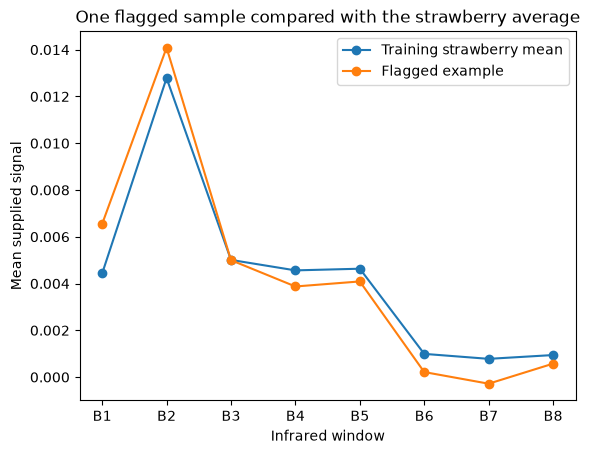

Example row: 940


In [9]:
example_id = review.loc[review["Flagged"]].index[0]
authentic_training.mean().plot(label="Training strawberry mean", marker="o")
X_test.loc[example_id].plot(label="Flagged example", marker="o")
plt.title("One flagged sample compared with the strawberry average")
plt.xlabel("Infrared window")
plt.ylabel("Mean supplied signal")
plt.legend()
plt.show()
print("Example row:", example_id)

### Stop and explain 3

In which windows does this example differ most visibly from the strawberry
average? Give one possible laboratory explanation for unusual measurements,
and one check you would make before rejecting the product.

Suggested answer for the saved example (row 940): The largest
absolute differences from the training mean are in B1, B2, B7. This plot
helps us inspect the example; it does not explain the forest's decision
or establish the cause. A different fruit, unusual authentic composition,
sample preparation or an instrument problem could affect measurements.
Check the sample identity and preparation, inspect instrument quality
controls, and repeat the measurement as appropriate before deciding.

## 5. Reveal the reference labels

Now add the known test labels to our review table. They did not enter the
detector's training or its flagging boundary. `crosstab` counts how often
each label occurs with and without a flag. Read a row across: its two
numbers add up to the number of test samples with that reference label.

NON-Strawberry includes other fruits and adulterated strawberry mixtures;
this file does not tell us which is which for individual samples.

As with the mistake tables in Foundations and Evaluation, rows show
reference labels. Here the columns mean Not flagged and Flagged,
rather than predicted classes. A flag requests review; it is not
a NON-Strawberry prediction. There is no classification accuracy here.

In [10]:
review["Reference"] = y_test
counts = pd.crosstab(review["Reference"], review["Flagged"])
counts = counts.rename(columns={False: "Not flagged", True: "Flagged"})
counts

Flagged,Not flagged,Flagged
Reference,,
NON-Strawberry,38,89
Strawberry,69,1


The next cell draws these same counts as bars. Taller bars mean more samples.
The two reference groups have different sizes, so compare each flagged
count with the total in its own row of the table above.

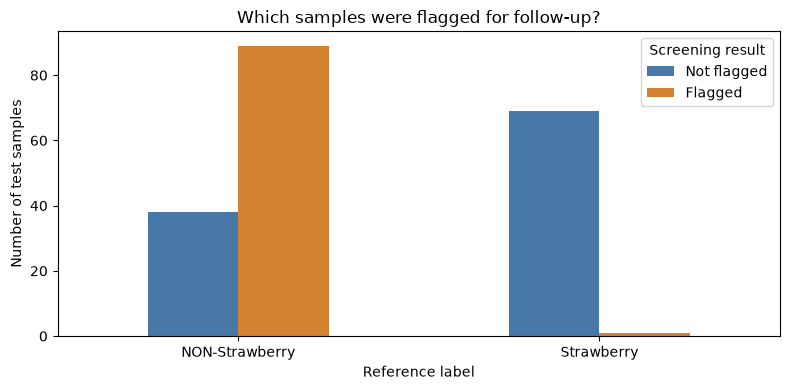

In [11]:
counts.plot.bar(color=["#4878A8", "#D58232"], rot=0, figsize=(8, 4))
plt.ylabel("Number of test samples")
plt.xlabel("Reference label")
plt.title("Which samples were flagged for follow-up?")
plt.legend(title="Screening result")
plt.tight_layout()
plt.show()

### Stop and explain 4

How many labelled Strawberry samples were flagged?
How many NON-Strawberry samples escaped a flag? Give one laboratory
consequence of each outcome. Use the table to support your answer.

Suggested answer for the saved run: Of the 70 labelled Strawberry
test samples, 1 was flagged. Of the 127 NON-Strawberry test samples,
38 were not flagged and 89 were flagged. Follow-up on a labelled
Strawberry sample adds work but could still uncover a measurement
problem; an unflagged NON-Strawberry sample would pass this screen.
Neither outcome establishes an adulterant's identity or concentration.

## 6. Decide what the laboratory should do

A flag can prioritise follow-up work. An authentic sample can be unusual;
a different fruit or mixture can resemble the reference measurements.
Not flagged does not certify purity. This screen cannot identify an
adulterant or measure its amount.

The test group was also used in the earlier practicals. Reusing it here
is a classroom demonstration, not new independent validation. The file
lacks supplier, batch and physical-specimen IDs. A laboratory would need
independent samples and a justified flagging boundary before routine use.

### Stop and explain 5

The manager proposes releasing every unflagged sample and discarding every
flagged one. Write two or three sentences explaining what you recommend
instead, using one result from this practical.

Example: Use this detector to prioritise checks, because 38
NON-Strawberry test samples escaped a flag and the flagged group included
one sample labelled Strawberry. Investigate flags through sample records,
measurement quality checks and suitable confirmatory analysis rather than
automatically discarding products. Validate the screen and its boundary
on independent samples before using it to support release decisions.

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.

Detector reference: [scikit-learn isolation forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html).